# Notebook 06 — Performance of Model 2: Gradient Boosting

**Research topic:** *A Machine Learning Approach to Predicting Retail Investor Dormancy on Digital Investment Platforms*

This notebook evaluates Gradient Boosting using the same test-set framework as Logistic Regression.

In [2]:

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, precision_score,
    recall_score, f1_score, roc_auc_score, average_precision_score,
    matthews_corrcoef, log_loss, brier_score_loss, confusion_matrix,
    ConfusionMatrixDisplay, RocCurveDisplay, PrecisionRecallDisplay)

from sklearn.calibration import calibration_curve
from scipy.stats import chi2_contingency
from statsmodels.stats.contingency_tables import mcnemar

DATA_FILE = Path("outputs/dormancy_modelling_dataset.csv")
OUTPUT_DIR = Path("outputs")
OUTPUT_DIR.mkdir(exist_ok=True)
RANDOM_STATE = 42
TEST_SIZE = 0.20
THRESHOLD = 0.50

df = pd.read_csv(DATA_FILE)
X = df.drop(columns=["customer_id", "dormant"])
y = df["dormant"]
categorical_cols = X.select_dtypes(include=["object"]).columns.tolist()
numeric_cols = [c for c in X.columns if c not in categorical_cols]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=TEST_SIZE, stratify=y, random_state=RANDOM_STATE)


In [3]:

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median"))
])
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False))
])
preprocessor = ColumnTransformer([
    ("num", numeric_pipeline, numeric_cols),
    ("cat", categorical_pipeline, categorical_cols)
])
X_train_gb = preprocessor.fit_transform(X_train)
X_test_gb = preprocessor.transform(X_test)

positive = y_train.sum()
negative = len(y_train)-positive
weights = np.where(y_train==1,len(y_train)/(2*positive), len(y_train)/(2*negative))

model = GradientBoostingClassifier(
    n_estimators=200, learning_rate=0.05, max_depth=3,
    min_samples_leaf=20, subsample=0.80, random_state=RANDOM_STATE)

model.fit(X_train_gb,y_train,sample_weight=weights)
prob = model.predict_proba(X_test_gb)[:,1]
pred = (prob >= THRESHOLD).astype(int)


In [4]:

def evaluate(y_true, pred, prob):
    tn, fp, fn, tp = confusion_matrix(y_true, pred, labels=[0,1]).ravel()
    specificity = tn / (tn + fp) if tn + fp else 0
    return {
        "Accuracy": accuracy_score(y_true,pred),
        "Balanced Accuracy": balanced_accuracy_score(y_true,pred),
        "Precision": precision_score(y_true,pred,zero_division=0),
        "Recall": recall_score(y_true,pred,zero_division=0),
        "Specificity": specificity,
        "F1-score": f1_score(y_true,pred,zero_division=0),
        "ROC-AUC": roc_auc_score(y_true,prob),
        "PR-AUC": average_precision_score(y_true,prob),
        "MCC": matthews_corrcoef(y_true,pred),
        "Log Loss": log_loss(y_true,prob),
        "Brier Score": brier_score_loss(y_true,prob),
        "TP": tp, "TN": tn, "FP": fp, "FN": fn
    }


In [5]:

results = evaluate(y_test,pred,prob)
display(pd.DataFrame([results]).round(4))
pd.DataFrame([results]).to_csv(
    OUTPUT_DIR/"gradient_boosting_performance.csv",index=False)


,Accuracy,Balanced Accuracy,Precision,Recall,Specificity,F1-score,ROC-AUC,PR-AUC,MCC,Log Loss,Brier Score,TP,TN,FP,FN
0,0.7712,0.7891,0.0542,0.8077,0.7706,0.1015,0.8624,0.0671,0.1703,0.3768,0.1363,126,7389,2200,30


## Confusion matrix

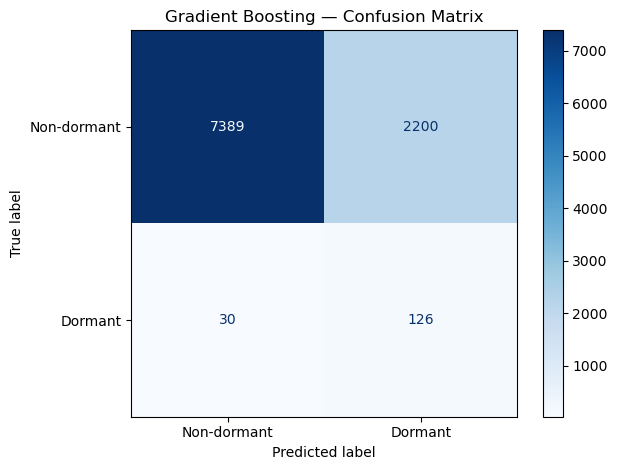

In [6]:

ConfusionMatrixDisplay.from_predictions(
    y_test,pred,display_labels=["Non-dormant","Dormant"],cmap="Blues")

plt.title("Gradient Boosting — Confusion Matrix")
plt.tight_layout()
plt.savefig(OUTPUT_DIR/"gb_performance_confusion_matrix.png",dpi=300)
plt.show()


## ROC and Precision-Recall curves

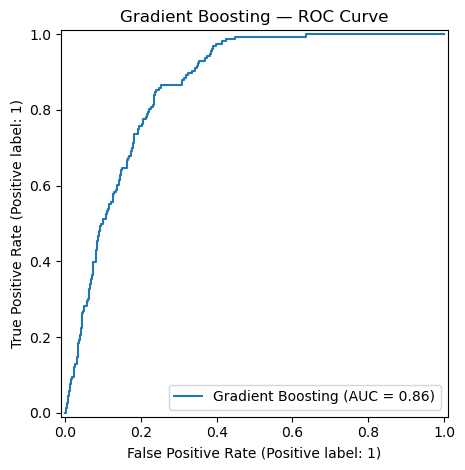

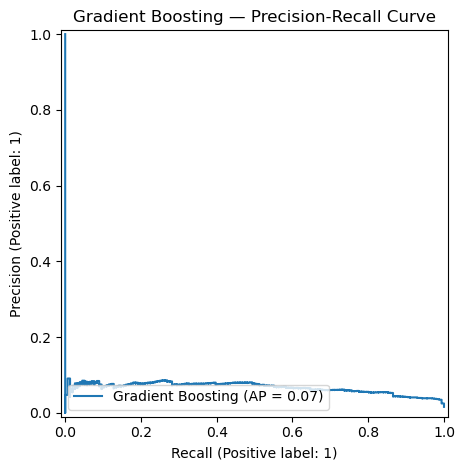

In [7]:

RocCurveDisplay.from_predictions(y_test,prob,name="Gradient Boosting")
plt.title("Gradient Boosting — ROC Curve")
plt.tight_layout()
plt.savefig(OUTPUT_DIR/"gb_performance_roc_curve.png",dpi=300)
plt.show()

PrecisionRecallDisplay.from_predictions(y_test,prob,name="Gradient Boosting")
plt.title("Gradient Boosting — Precision-Recall Curve")
plt.tight_layout()
plt.savefig(OUTPUT_DIR/"gb_performance_precision_recall_curve.png",dpi=300)
plt.show()


## Calibration

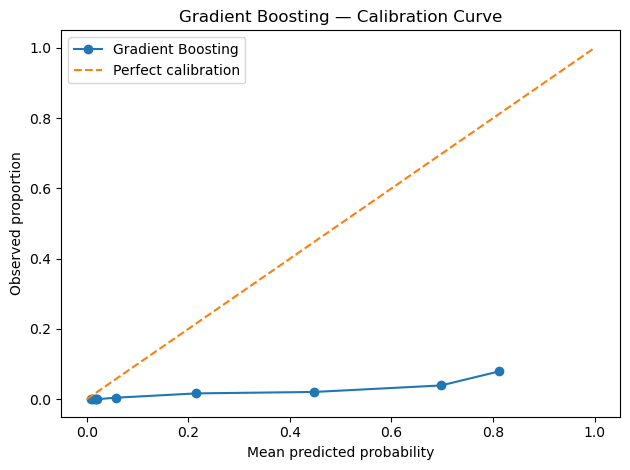

In [8]:

true_prob, predicted_prob = calibration_curve(
    y_test,prob,n_bins=10,strategy="quantile"
)
plt.plot(predicted_prob,true_prob,"o-",label="Gradient Boosting")
plt.plot([0,1],[0,1],"--",label="Perfect calibration")
plt.xlabel("Mean predicted probability")
plt.ylabel("Observed proportion")
plt.title("Gradient Boosting — Calibration Curve")
plt.legend()
plt.tight_layout()
plt.savefig(OUTPUT_DIR/"gb_performance_calibration_curve.png",dpi=300)
plt.show()


## Interpretation and impact

Gradient Boosting can model nonlinear relationships and interactions between investor characteristics and historical transaction behaviour. Its recall indicates how effectively it identifies investors who become dormant, while precision indicates the reliability of those alerts.

PR-AUC is important because the dormant class may be less common than the non-dormant class. Probability measures such as Brier score and log loss are useful when the platform wants to prioritise investors according to predicted dormancy risk rather than use only a binary classification.

The practical impact should be interpreted through false negatives and false positives: missed dormant investors may reduce the reach of retention efforts, while false alerts can increase intervention costs or create unnecessary customer contact.